In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = load_wine(as_frame=True)

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Features:", list(X.columns))
print("Missing values:", X.isnull().sum().sum())

Dataset shape: (178, 13)
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Missing values: 0


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 142
Testing samples: 36


In [4]:
model_all = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_all.fit(X_train, y_train)

pred_all = model_all.predict(X_test)

accuracy_all = accuracy_score(y_test, pred_all)

print("Accuracy using all features:", round(accuracy_all, 4))

Accuracy using all features: 1.0


Feature Importance:
color_intensity                 0.187580
flavanoids                      0.159561
proline                         0.146799
alcohol                         0.117913
hue                             0.101538
od280/od315_of_diluted_wines    0.096301
total_phenols                   0.041514
magnesium                       0.040131
malic_acid                      0.033894
alcalinity_of_ash               0.025471
proanthocyanins                 0.023530
ash                             0.018157
nonflavanoid_phenols            0.007610
dtype: float64


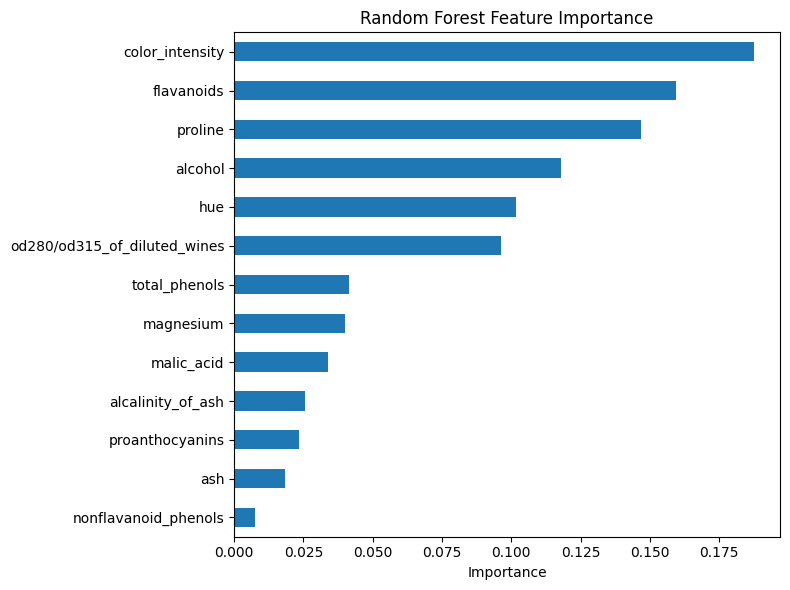

In [5]:
importance = pd.Series(
    model_all.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(importance)

importance.sort_values().plot(
    kind="barh",
    figsize=(8, 6),
    title="Random Forest Feature Importance"
)

plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [6]:
top5_features = importance.head(5).index.tolist()

print("Top 5 Features:", top5_features)

model_top5 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model_top5.fit(X_train[top5_features], y_train)

pred_top5 = model_top5.predict(X_test[top5_features])

accuracy_top5 = accuracy_score(y_test, pred_top5)

print("Accuracy using all features:", round(accuracy_all, 4))
print("Accuracy using top 5 features:", round(accuracy_top5, 4))

Top 5 Features: ['color_intensity', 'flavanoids', 'proline', 'alcohol', 'hue']
Accuracy using all features: 1.0
Accuracy using top 5 features: 1.0


In [7]:
results_df = pd.DataFrame({
    "Model": ["All Features", "Top 5 Features"],
    "Number of Features": [X.shape[1], len(top5_features)],
    "Accuracy": [accuracy_all, accuracy_top5]
})

print(results_df)

results_df.to_csv("assignment7_results.csv", index=False)

            Model  Number of Features  Accuracy
0    All Features                  13       1.0
1  Top 5 Features                   5       1.0
